<a href="https://colab.research.google.com/github/adecool/machine-learning---unsupervised-10-projects/blob/main/Industrial%20Equipment%20Anomaly%20detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install ucimlrepo

from ucimlrepo import fetch_ucirepo
import pandas as pd

dataset = fetch_ucirepo(id=601)

X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)

print("Dataset shape:", df.shape)
display(df.head())
display(df.info())

Dataset shape: (10000, 12)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Type                 10000 non-null  object 
 1   Air temperature      10000 non-null  float64
 2   Process temperature  10000 non-null  float64
 3   Rotational speed     10000 non-null  int64  
 4   Torque               10000 non-null  float64
 5   Tool wear            10000 non-null  int64  
 6   Machine failure      10000 non-null  int64  
 7   TWF                  10000 non-null  int64  
 8   HDF                  10000 non-null  int64  
 9   PWF                  10000 non-null  int64  
 10  OSF                  10000 non-null  int64  
 11  RNF                  10000 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 937.6+ KB


None

In [2]:
print(df.columns.tolist())

['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


In [3]:
failure_counts = df["Machine failure"].value_counts()

failure_percent = (
    df["Machine failure"]
    .value_counts(normalize=True) * 100
)

print("Failure counts:")
print(failure_counts)

print("\nFailure percentages:")
print(failure_percent.round(2))

Failure counts:
Machine failure
0    9661
1     339
Name: count, dtype: int64

Failure percentages:
Machine failure
0    96.61
1     3.39
Name: proportion, dtype: float64


In [4]:
failure_columns = [
    "TWF", "HDF", "PWF", "OSF", "RNF"
]

failure_summary = pd.DataFrame({
    "Failure_Count": df[failure_columns].sum(),
    "Failure_Rate_%": (
        df[failure_columns].mean() * 100
    )
})

display(failure_summary.round(2))

,Failure_Count,Failure_Rate_%
TWF,46,0.46
HDF,115,1.15
PWF,95,0.95
OSF,98,0.98
RNF,19,0.19


In [5]:
failure_columns = ["TWF", "HDF", "PWF", "OSF", "RNF"]

df["Failure_Type_Count"] = df[failure_columns].sum(axis=1)

print("Number of failure types per observation:")
print(df["Failure_Type_Count"].value_counts().sort_index())

print("\nOverall failures with no failure-type flag:")
print(
    (
        (df["Machine failure"] == 1) &
        (df["Failure_Type_Count"] == 0)
    ).sum()
)

print("\nNo overall failure but a failure-type flag:")
print(
    (
        (df["Machine failure"] == 0) &
        (df["Failure_Type_Count"] > 0)
    ).sum()
)

Number of failure types per observation:
Failure_Type_Count
0    9652
1     324
2      23
3       1
Name: count, dtype: int64

Overall failures with no failure-type flag:
9

No overall failure but a failure-type flag:
18


In [6]:
sensor_columns = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

display(
    df[sensor_columns].describe().T.round(2)
)

,count,mean,std,min,25%,50%,75%,max
Air temperature,10000.0,300.00,2.00,295.3,298.3,300.1,301.5,304.5
Process temperature,10000.0,310.01,1.48,305.7,308.8,310.1,311.1,313.8
Rotational speed,10000.0,1538.78,179.28,1168.0,1423.0,1503.0,1612.0,2886.0
Torque,10000.0,39.99,9.97,3.8,33.2,40.1,46.8,76.6
Tool wear,10000.0,107.95,63.65,0.0,53.0,108.0,162.0,253.0


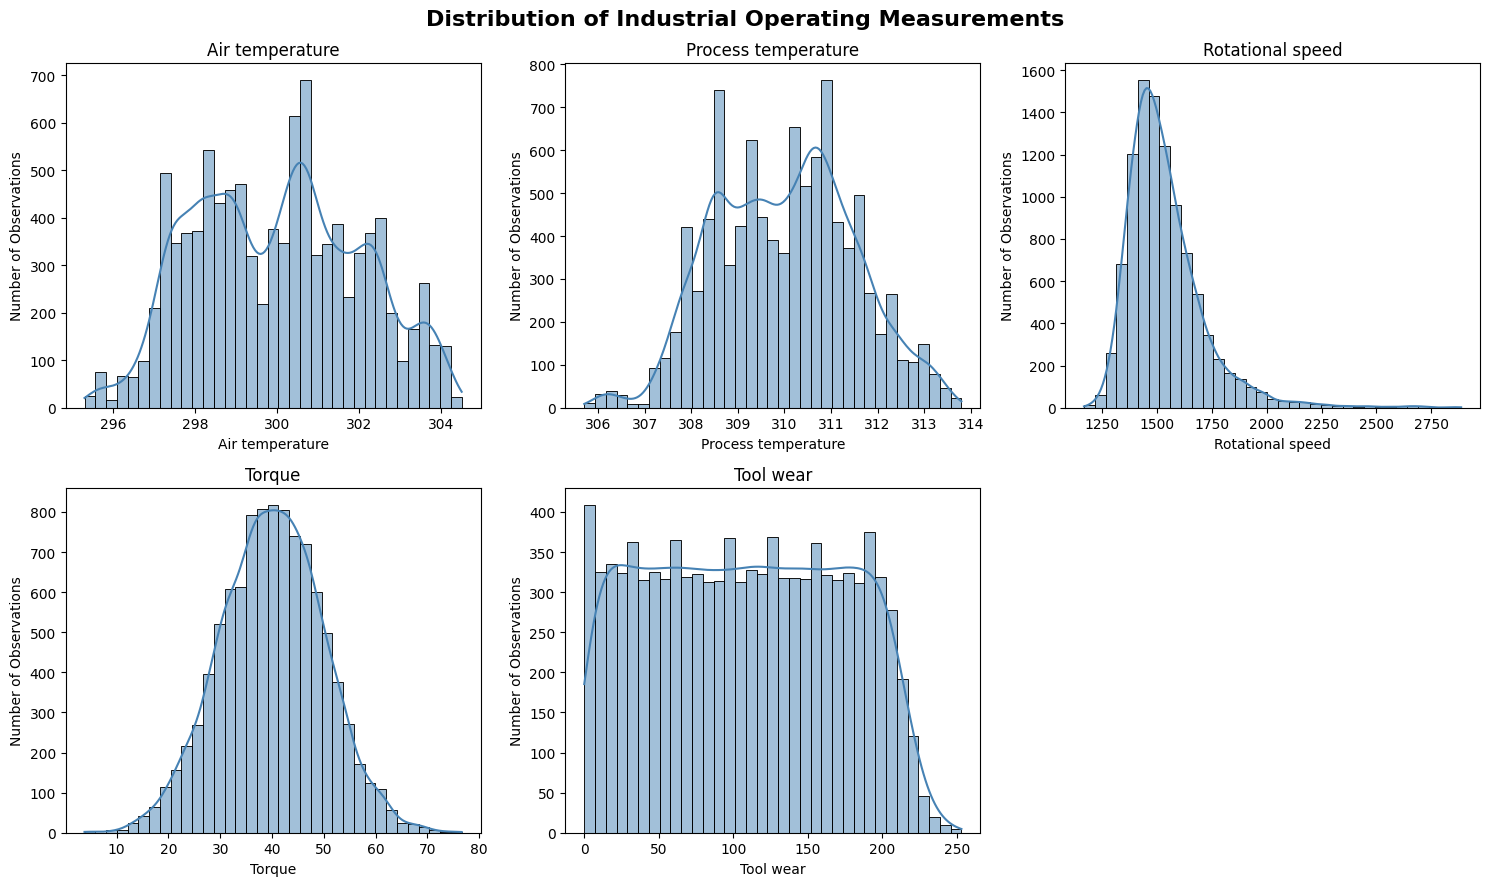

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sensor_columns = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, column in enumerate(sensor_columns):
    sns.histplot(
        data=df,
        x=column,
        bins=35,
        kde=True,
        ax=axes[i],
        color="steelblue"
    )

    axes[i].set_title(column)
    axes[i].set_ylabel("Number of Observations")

axes[-1].axis("off")

plt.suptitle(
    "Distribution of Industrial Operating Measurements",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

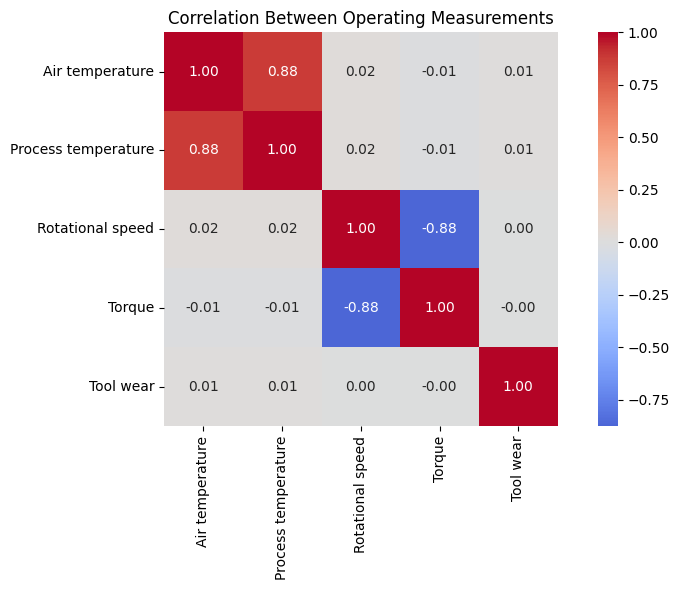

In [8]:
correlation_matrix = df[sensor_columns].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0,
    square=True
)

plt.title("Correlation Between Operating Measurements")
plt.tight_layout()
plt.show()

In [9]:
import numpy as np

df["Mechanical_Power_kW"] = (
    2 * np.pi *
    df["Rotational speed"] *
    df["Torque"]
) / 60000

df["Temperature_Difference"] = (
    df["Process temperature"] -
    df["Air temperature"]
)

display(
    df[
        ["Mechanical_Power_kW", "Temperature_Difference"]
    ].describe().T.round(2)
)

,count,mean,std,min,25%,50%,75%,max
Mechanical_Power_kW,10000.0,6.28,1.07,1.15,5.56,6.27,7.0,10.47
Temperature_Difference,10000.0,10.00,1.00,7.60,9.30,9.80,11.0,12.10


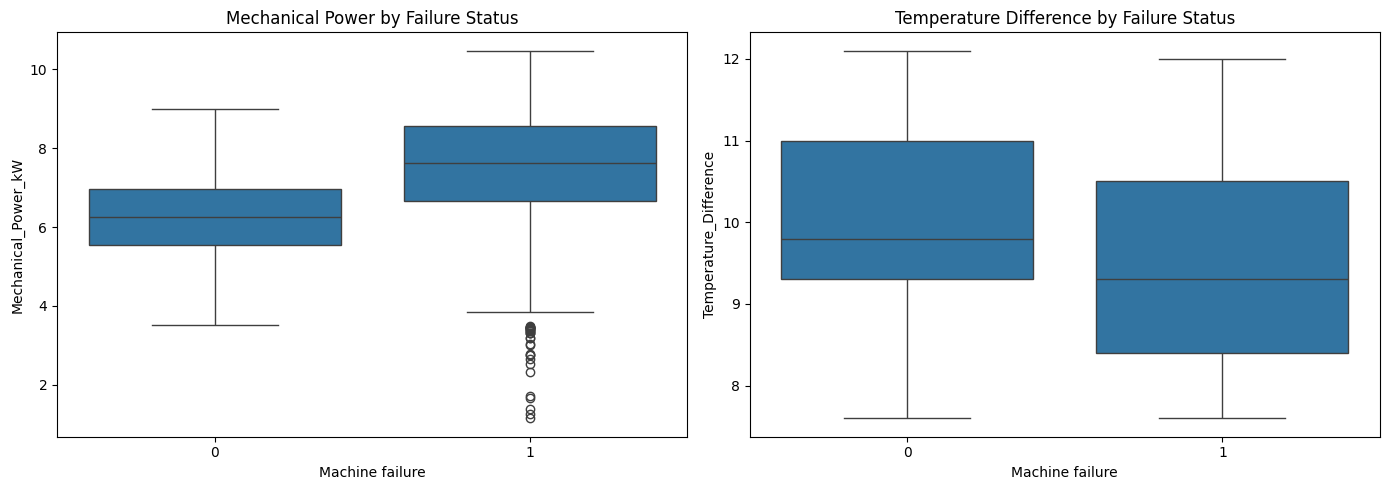

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Mechanical_Power_kW",
    ax=axes[0]
)

axes[0].set_title(
    "Mechanical Power by Failure Status"
)

sns.boxplot(
    data=df,
    x="Machine failure",
    y="Temperature_Difference",
    ax=axes[1]
)

axes[1].set_title(
    "Temperature Difference by Failure Status"
)

plt.tight_layout()
plt.show()

In [11]:
feature_comparison = df.groupby(
    "Machine failure"
)[
    [
        "Mechanical_Power_kW",
        "Temperature_Difference",
        "Rotational speed",
        "Torque",
        "Tool wear"
    ]
].agg(["mean", "median", "std"])

display(feature_comparison.round(2))

Mechanical_Power_kW              Temperature_Difference  \
                               mean median   std                   mean   
Machine failure                                                           
0                              6.24   6.24  1.01                  10.02   
1                              7.28   7.61  1.85                   9.40   

                             Rotational speed                 Torque         \
                median   std             mean  median     std   mean median   
Machine failure                                                               
0                  9.8  0.99          1540.26  1507.0  167.39  39.63   39.9   
1                  9.3  1.16          1496.49  1365.0  384.94  50.17   53.7   

                       Tool wear                
                   std      mean median    std  
Machine failure                                 
0                 9.47    106.69  107.0  62.95  
1                16.37    143.78  165.0  72.76

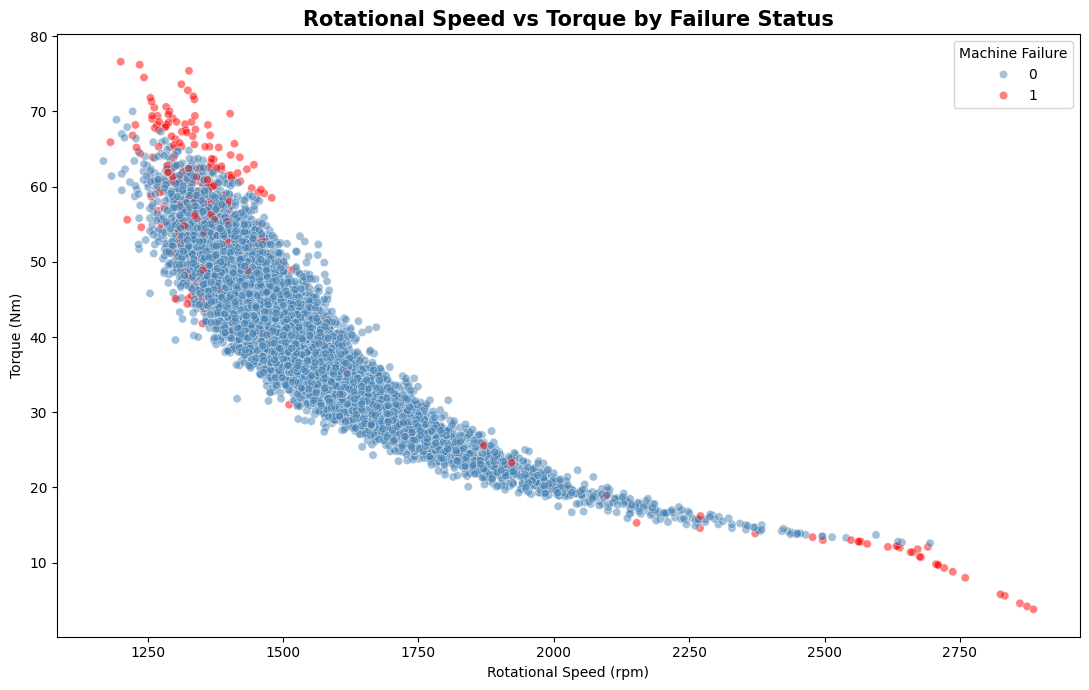

In [12]:
plt.figure(figsize=(11, 7))

sns.scatterplot(
    data=df,
    x="Rotational speed",
    y="Torque",
    hue="Machine failure",
    palette={0: "steelblue", 1: "red"},
    alpha=0.5,
    s=35
)

plt.title(
    "Rotational Speed vs Torque by Failure Status",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Rotational Speed (rpm)")
plt.ylabel("Torque (Nm)")
plt.legend(title="Machine Failure")

plt.tight_layout()
plt.show()

In [13]:
power_analysis = (
    df.assign(
        Power_Band=pd.qcut(
            df["Mechanical_Power_kW"],
            q=10,
            duplicates="drop"
        )
    )
    .groupby("Power_Band", observed=True)
    .agg(
        Observations=("Machine failure", "size"),
        Failures=("Machine failure", "sum"),
        Failure_Rate=("Machine failure", "mean")
    )
)

power_analysis["Failure_Rate_%"] = (
    power_analysis["Failure_Rate"] * 100
)

display(
    power_analysis[
        ["Observations", "Failures", "Failure_Rate_%"]
    ].round(2)
)

,Observations,Failures,Failure_Rate_%
Power_Band,,,
"(1.147, 4.915]",1000,40,4.0
"(4.915, 5.383]",1000,6,0.6
"(5.383, 5.718]",1000,5,0.5
"(5.718, 6.008]",1000,8,0.8
"(6.008, 6.271]",1000,12,1.2
"(6.271, 6.547]",1000,9,0.9
"(6.547, 6.833]",1000,24,2.4
"(6.833, 7.176]",1000,26,2.6
"(7.176, 7.641]",1000,40,4.0


In [14]:
from sklearn.preprocessing import StandardScaler

baseline_features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

X_baseline = df[baseline_features].copy()

scaler_baseline = StandardScaler()

X_baseline_scaled = scaler_baseline.fit_transform(
    X_baseline
)

print("Original shape:", X_baseline.shape)
print("Scaled shape:", X_baseline_scaled.shape)

print("\nScaled feature means:")
print(
    X_baseline_scaled.mean(axis=0).round(4)
)

print("\nScaled feature standard deviations:")
print(
    X_baseline_scaled.std(axis=0).round(4)
)

Original shape: (10000, 5)
Scaled shape: (10000, 5)

Scaled feature means:
[-0.  0. -0.  0.  0.]

Scaled feature standard deviations:
[1. 1. 1. 1. 1.]


In [15]:
from sklearn.model_selection import train_test_split

# Features: original operating measurements only
X = df[baseline_features].copy()

# Labels: reserved for evaluation
y = df["Machine failure"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining failure rate:")
print(y_train.mean().round(4))

print("\nTesting failure rate:")
print(y_test.mean().round(4))

Training observations: 8000
Testing observations: 2000

Training failure rate:
0.0339

Testing failure rate:
0.034


In [16]:
from sklearn.ensemble import IsolationForest

iso_baseline = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

iso_baseline.fit(X_train)

# Predict anomalies on unseen test observations
test_predictions = iso_baseline.predict(X_test)

print("Prediction values:")
print(pd.Series(test_predictions).value_counts())

Prediction values:
 1    1899
-1     101
Name: count, dtype: int64


In [17]:
import pandas as pd

results = X_test.copy()

results["Actual_Failure"] = y_test
results["Anomaly_Flag"] = (
    test_predictions == -1
).astype(int)

results["Anomaly_Score"] = (
    -iso_baseline.score_samples(X_test)
)

display(results.head())

print("\nAnomalies flagged:")
print(results["Anomaly_Flag"].sum())

print("\nRecorded failures in test set:")
print(results["Actual_Failure"].sum())

,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Actual_Failure,Anomaly_Flag,Anomaly_Score
2997,300.5,309.8,1345,62.7,153,0,0,0.496751
4871,303.7,312.4,1513,40.1,135,0,0,0.478832
3858,302.5,311.4,1559,37.6,209,0,0,0.467097
951,295.6,306.3,1509,35.8,60,0,1,0.595391
6463,300.5,310.0,1358,60.4,102,0,0,0.481916



Anomalies flagged:
101

Recorded failures in test set:
68


              precision    recall  f1-score   support

  No Failure       0.97      0.95      0.96      1932
     Failure       0.09      0.13      0.11        68

    accuracy                           0.92      2000
   macro avg       0.53      0.54      0.53      2000
weighted avg       0.94      0.92      0.93      2000



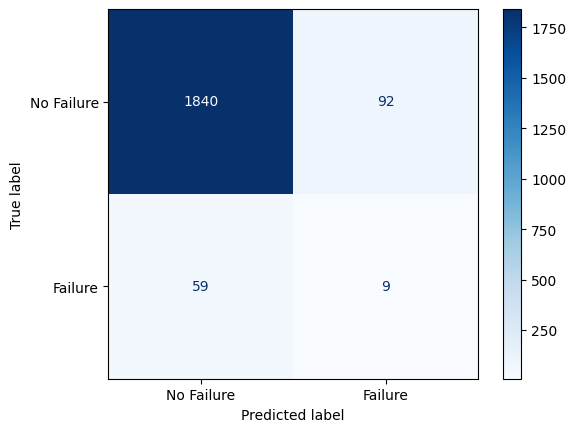

In [18]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

y_true = results["Actual_Failure"]
y_pred = results["Anomaly_Flag"]

cm = confusion_matrix(y_true, y_pred)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Failure", "Failure"]
).plot(cmap="Blues")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=["No Failure", "Failure"],
        zero_division=0
    )
)

In [19]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Calculate mechanical power from speed and torque
train_power = (
    2 * np.pi
    * X_train["Rotational speed"]
    * X_train["Torque"]
    / 60000
)

test_power = (
    2 * np.pi
    * X_test["Rotational speed"]
    * X_test["Torque"]
    / 60000
)

# Define the high-power threshold using training data only
power_threshold = train_power.quantile(0.90)

# Flag observations above the threshold
power_predictions = (
    test_power > power_threshold
).astype(int)

print("Power threshold:", round(power_threshold, 3), "kW")

print("\nPower-rule confusion matrix:")
print(confusion_matrix(y_test, power_predictions))

print("\nPower-rule precision:",
      round(precision_score(y_test, power_predictions), 4))

print("Power-rule recall:",
      round(recall_score(y_test, power_predictions), 4))

print("Power-rule F1:",
      round(f1_score(y_test, power_predictions), 4))

print("\nObservations flagged:",
      power_predictions.sum())

Power threshold: 7.641 kW

Power-rule confusion matrix:
[[1767  165]
 [  32   36]]

Power-rule precision: 0.1791
Power-rule recall: 0.5294
Power-rule F1: 0.2677

Observations flagged: 201


In [20]:
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd
import numpy as np

inspection_budget = 100

# Rank by Isolation Forest anomaly score
forest_scores = pd.Series(
    -iso_baseline.score_samples(X_test),
    index=X_test.index
)

# Rank by mechanical power
power_scores = pd.Series(
    test_power,
    index=X_test.index
)

def evaluate_top_k(scores, y_true, k):
    selected = scores.nlargest(k).index

    predictions = pd.Series(
        0,
        index=scores.index
    )

    predictions.loc[selected] = 1

    return {
        "Flagged": int(predictions.sum()),
        "Failures Detected": int(
            ((predictions == 1) & (y_true == 1)).sum()
        ),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1": f1_score(y_true, predictions)
    }

comparison = pd.DataFrame({
    "Isolation Forest": evaluate_top_k(
        forest_scores, y_test, inspection_budget
    ),
    "Power Rule": evaluate_top_k(
        power_scores, y_test, inspection_budget
    )
}).T

display(comparison.round(4))

,Flagged,Failures Detected,Precision,Recall,F1
Isolation Forest,100.0,9.0,0.09,0.1324,0.1071
Power Rule,100.0,27.0,0.27,0.3971,0.3214


In [21]:
from sklearn.ensemble import IsolationForest
from sklearn.metrics import precision_score, recall_score, f1_score
import pandas as pd

# Original five measurements
baseline_features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

# Recreate the engineered measurements
df["Mechanical_Power_kW"] = (
    2 * np.pi
    * df["Rotational speed"]
    * df["Torque"]
    / 60000
)

df["Temperature_Difference"] = (
    df["Process temperature"]
    - df["Air temperature"]
)

# Combine original and engineered features
engineered_features = baseline_features + [
    "Mechanical_Power_kW",
    "Temperature_Difference"
]

print("Features available:")
print(engineered_features)

print("\nFeature count:", len(engineered_features))

# Keep the same train/test rows
X_train_eng = df.loc[
    X_train.index, engineered_features
].copy()

X_test_eng = df.loc[
    X_test.index, engineered_features
].copy()

# Train the engineered Isolation Forest
iso_engineered = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

iso_engineered.fit(X_train_eng)

# Higher score = more anomalous
engineered_scores = pd.Series(
    -iso_engineered.score_samples(X_test_eng),
    index=X_test_eng.index
)

# Use the same inspection budget of 100
engineered_results = evaluate_top_k(
    engineered_scores,
    y_test,
    k=100
)

print("Engineered Isolation Forest:")
display(
    pd.DataFrame(
        engineered_results,
        index=["Engineered Model"]
    ).round(4)
)

Features available:
['Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Mechanical_Power_kW', 'Temperature_Difference']

Feature count: 7
Engineered Isolation Forest:


,Flagged,Failures Detected,Precision,Recall,F1
Engineered Model,100,20,0.2,0.2941,0.2381


In [22]:
comparison_final = pd.DataFrame({
    "Baseline Isolation Forest": evaluate_top_k(
        forest_scores, y_test, 100
    ),
    "Engineered Isolation Forest": evaluate_top_k(
        engineered_scores, y_test, 100
    ),
    "Mechanical Power Rule": evaluate_top_k(
        power_scores, y_test, 100
    )
}).T

display(comparison_final.round(4))

,Flagged,Failures Detected,Precision,Recall,F1
Baseline Isolation Forest,100.0,9.0,0.09,0.1324,0.1071
Engineered Isolation Forest,100.0,20.0,0.20,0.2941,0.2381
Mechanical Power Rule,100.0,27.0,0.27,0.3971,0.3214


In [23]:
# Select top 100 observations for each method
power_top100 = set(
    power_scores.nlargest(100).index
)

engineered_top100 = set(
    engineered_scores.nlargest(100).index
)

# Actual failure observations in the test set
actual_failures = set(
    y_test[y_test == 1].index
)

# Failures detected by each approach
power_detected = power_top100 & actual_failures
engineered_detected = engineered_top100 & actual_failures

# Compare detected failures
both_detected = power_detected & engineered_detected

power_only = power_detected - engineered_detected

engineered_only = engineered_detected - power_detected

combined_detected = power_detected | engineered_detected

print("Failures detected by both:",
      len(both_detected))

print("Failures detected only by power rule:",
      len(power_only))

print("Failures detected only by engineered IF:",
      len(engineered_only))

print("Unique failures detected by either:",
      len(combined_detected))

print("Failures missed by both:",
      len(actual_failures - combined_detected))

Failures detected by both: 12
Failures detected only by power rule: 15
Failures detected only by engineered IF: 8
Unique failures detected by either: 35
Failures missed by both: 33


In [24]:
# Inspect the eight failures detected only by engineered IF
failure_type_columns = [
    "TWF", "HDF", "PWF", "OSF", "RNF"
]

columns_to_inspect = [
    "Rotational speed",
    "Torque",
    "Tool wear",
    "Mechanical_Power_kW",
    "Temperature_Difference",
    "Machine failure"
] + failure_type_columns

engineered_only_df = df.loc[
    sorted(engineered_only),
    columns_to_inspect
].copy()

display(engineered_only_df.round(2))

print("\nFailure-type counts among these observations:")
print(
    engineered_only_df[failure_type_columns].sum()
)

,Rotational speed,Torque,Tool wear,Mechanical_Power_kW,Temperature_Difference,Machine failure,TWF,HDF,PWF,OSF,RNF
380,2564,12.8,127,3.44,10.8,1,0,0,1,0,0
926,1372,55.6,215,7.99,10.5,1,0,0,0,1,0
1391,2737,8.8,142,2.52,11.3,1,0,0,1,0,0
2941,1996,19.8,203,4.14,8.9,1,1,0,0,0,0
4296,2825,5.8,215,1.72,8.4,1,0,0,1,0,0
5399,1411,53.8,246,7.95,9.6,1,0,0,0,1,0
7011,2633,12.2,17,3.36,10.0,1,0,0,1,0,0
7997,2710,9.7,143,2.75,11.2,1,0,0,1,0,0



Failure-type counts among these observations:
TWF    1
HDF    0
PWF    5
OSF    2
RNF    0
dtype: int64


In [25]:
# All observations flagged by either method
combined_alerts = power_top100 | engineered_top100

# Number of unique alerts
total_combined_alerts = len(combined_alerts)

# Number of recorded failures detected
combined_true_positives = len(
    combined_alerts & actual_failures
)

combined_precision = (
    combined_true_positives / total_combined_alerts
)

combined_recall = (
    combined_true_positives / len(actual_failures)
)

print("Total unique alerts:", total_combined_alerts)

print("Recorded failures detected:",
      combined_true_positives)

print("Combined precision:",
      round(combined_precision, 4))

print("Combined recall:",
      round(combined_recall, 4))

print("Alert overlap:",
      len(power_top100 & engineered_top100))

Total unique alerts: 181
Recorded failures detected: 35
Combined precision: 0.1934
Combined recall: 0.5147
Alert overlap: 19


In [26]:
combined_alerts = power_top100 | engineered_top100

total_alerts = len(combined_alerts)

detected_failures = len(
    combined_alerts & actual_failures
)

print("Total unique alerts:", total_alerts)
print("Failures detected:", detected_failures)
print("Precision:", round(detected_failures / total_alerts, 4))
print("Recall:", round(detected_failures / len(actual_failures), 4))
print("Overlapping alerts:",
      len(power_top100 & engineered_top100))

Total unique alerts: 181
Failures detected: 35
Precision: 0.1934
Recall: 0.5147
Overlapping alerts: 19


In [27]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

# Separate operating observations and failure labels
X = df.drop(columns=[
    "Machine failure",
    "TWF", "HDF", "PWF", "OSF", "RNF"
])

y = df["Machine failure"]

# Split into 60% training and 40% temporary data
X_train9, X_temp9, y_train9, y_temp9 = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=123,
    stratify=y
)

# Divide temporary data equally
X_val9, X_test9, y_val9, y_test9 = train_test_split(
    X_temp9,
    y_temp9,
    test_size=0.50,
    random_state=123,
    stratify=y_temp9
)

In [28]:
split_summary = pd.DataFrame({
    "Observations": [
        len(X_train9),
        len(X_val9),
        len(X_test9)
    ],
    "Recorded Failures": [
        y_train9.sum(),
        y_val9.sum(),
        y_test9.sum()
    ],
    "Failure Rate (%)": [
        y_train9.mean() * 100,
        y_val9.mean() * 100,
        y_test9.mean() * 100
    ]
}, index=[
    "Training",
    "Validation",
    "Testing"
])

display(split_summary.round(2))

,Observations,Recorded Failures,Failure Rate (%)
Training,6000,203,3.38
Validation,2000,68,3.40
Testing,2000,68,3.40


In [29]:
def calculate_power(data):
    return (
        2 * np.pi
        * data["Rotational speed"]
        * data["Torque"]
        / 60000
    )

train_power9 = calculate_power(X_train9)
val_power9 = calculate_power(X_val9)

display(train_power9.describe())

,0
count,6000.000000
mean,6.273258
std,1.065333
min,1.264051
25%,5.553823
50%,6.276871
75%,7.002511
max,10.469923


In [30]:
# Establish reference distribution using training data
reference_power = np.sort(train_power9.values)

def calculate_percentile(values, reference):
    return (
        np.searchsorted(
            reference,
            values,
            side="right"
        ) / len(reference)
    )

# Compare validation power against training distribution
val_percentiles = calculate_percentile(
    val_power9.values,
    reference_power
)

# Two-sided anomaly scores
two_sided_scores = pd.Series(
    2 * np.abs(val_percentiles - 0.5),
    index=X_val9.index
)

In [31]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

def evaluate_top_k(scores, y_true, k=100):

    selected = scores.nlargest(k).index

    predictions = pd.Series(
        0, index=y_true.index
    )

    predictions.loc[selected] = 1

    return {
        "Flagged": int(predictions.sum()),

        "Failures Detected": int(
            ((predictions == 1) &
             (y_true == 1)).sum()
        ),

        "Precision": precision_score(
            y_true, predictions
        ),

        "Recall": recall_score(
            y_true, predictions
        ),

        "F1": f1_score(
            y_true, predictions
        )
    }

In [32]:
power_comparison = pd.DataFrame({

    "High-Power Rule": evaluate_top_k(
        val_power9,
        y_val9,
        k=100
    ),

    "Two-Sided Power Rule": evaluate_top_k(
        two_sided_scores,
        y_val9,
        k=100
    )

}).T

display(power_comparison.round(4))

,Flagged,Failures Detected,Precision,Recall,F1
High-Power Rule,100.0,29.0,0.29,0.4265,0.3452
Two-Sided Power Rule,100.0,33.0,0.33,0.4853,0.3929


In [33]:
def calculate_overstrain(data):
    return data["Torque"] * data["Tool wear"]

train_overstrain9 = calculate_overstrain(X_train9)

val_overstrain9 = calculate_overstrain(X_val9)

display(train_overstrain9.describe())

,0
count,6000.00000
mean,4268.73540
std,2801.54092
min,0.00000
25%,1914.02500
50%,3974.40000
75%,6247.27500
max,13864.40000


In [34]:
overstrain_analysis = pd.DataFrame({
    "Overstrain_Indicator": train_overstrain9,
    "Machine_Failure": y_train9
})

overstrain_analysis["Decile"] = pd.qcut(
    overstrain_analysis["Overstrain_Indicator"],
    q=10,
    duplicates="drop"
)

overstrain_summary = (
    overstrain_analysis
    .groupby("Decile", observed=True)
    .agg(
        Observations=("Machine_Failure", "count"),
        Failures=("Machine_Failure", "sum"),
        Failure_Rate=("Machine_Failure", "mean")
    )
)

overstrain_summary["Failure_Rate"] *= 100

display(overstrain_summary.round(2))

,Observations,Failures,Failure_Rate
Decile,,,
"(-0.001, 722.7]",600,16,2.67
"(722.7, 1498.4]",600,19,3.17
"(1498.4, 2352.27]",600,10,1.67
"(2352.27, 3188.64]",600,5,0.83
"(3188.64, 3974.4]",601,8,1.33
"(3974.4, 4842.72]",599,8,1.34
"(4842.72, 5720.66]",600,9,1.50
"(5720.66, 6789.26]",600,14,2.33
"(6789.26, 8226.08]",600,25,4.17


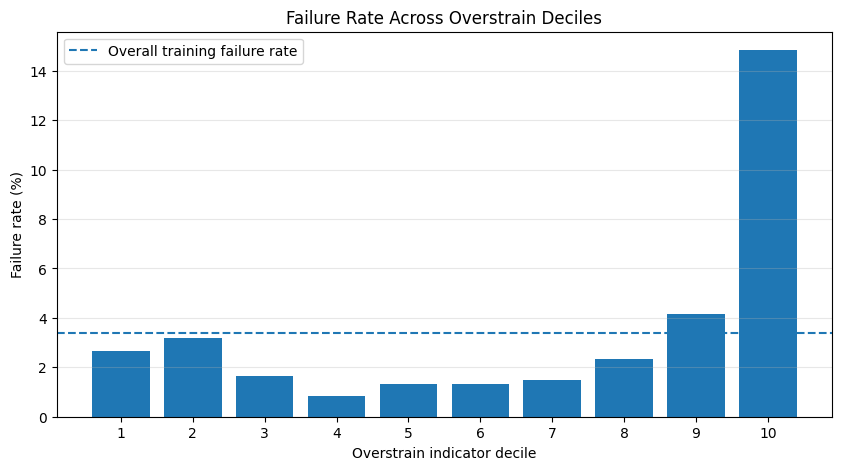

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    range(1, len(overstrain_summary) + 1),
    overstrain_summary["Failure_Rate"]
)

plt.axhline(
    y=y_train9.mean() * 100,
    linestyle="--",
    label="Overall training failure rate"
)

plt.xlabel("Overstrain indicator decile")
plt.ylabel("Failure rate (%)")
plt.title("Failure Rate Across Overstrain Deciles")
plt.xticks(range(1, len(overstrain_summary) + 1))
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()

In [36]:
overstrain_comparison = pd.DataFrame({

    "High-Power Rule": evaluate_top_k(
        val_power9,
        y_val9,
        k=100
    ),

    "Two-Sided Power Rule": evaluate_top_k(
        two_sided_scores,
        y_val9,
        k=100
    ),

    "Overstrain Rule": evaluate_top_k(
        val_overstrain9,
        y_val9,
        k=100
    )

}).T

display(overstrain_comparison.round(4))

,Flagged,Failures Detected,Precision,Recall,F1
High-Power Rule,100.0,29.0,0.29,0.4265,0.3452
Two-Sided Power Rule,100.0,33.0,0.33,0.4853,0.3929
Overstrain Rule,100.0,28.0,0.28,0.4118,0.3333


In [37]:
reference_overstrain = np.sort(
    train_overstrain9.values
)

overstrain_percentiles = calculate_percentile(
    val_overstrain9.values,
    reference_overstrain
)

overstrain_scores = pd.Series(
    overstrain_percentiles,
    index=X_val9.index
)

In [39]:
import numpy as np
import pandas as pd

# Calculate overstrain indicators
train_overstrain9 = (
    X_train9["Torque"] * X_train9["Tool wear"]
)

val_overstrain9 = (
    X_val9["Torque"] * X_val9["Tool wear"]
)

# Establish training reference distribution
reference_overstrain = np.sort(
    train_overstrain9.values
)

# Convert validation overstrain to percentile scores
overstrain_scores = pd.Series(
    np.searchsorted(
        reference_overstrain,
        val_overstrain9.values,
        side="right"
    ) / len(reference_overstrain),
    index=X_val9.index
)

# Create engineering scores dataframe
engineering_scores = pd.DataFrame({
    "Power_Score": two_sided_scores,
    "Overstrain_Score": overstrain_scores
})

# Maximum score
engineering_scores["Maximum_Score"] = (
    engineering_scores[
        ["Power_Score", "Overstrain_Score"]
    ].max(axis=1)
)

# Average score
engineering_scores["Average_Score"] = (
    engineering_scores[
        ["Power_Score", "Overstrain_Score"]
    ].mean(axis=1)
)

print("Shape:", engineering_scores.shape)

print("\nMissing values:")
print(engineering_scores.isna().sum())

display(engineering_scores.head())

Shape: (2000, 4)

Missing values:
Power_Score         0
Overstrain_Score    0
Maximum_Score       0
Average_Score       0
dtype: int64


,Power_Score,Overstrain_Score,Maximum_Score,Average_Score
5285,0.058333,0.720333,0.720333,0.389333
8667,0.518333,0.798833,0.798833,0.658583
9342,0.422333,0.039000,0.422333,0.230667
1564,0.954333,0.344667,0.954333,0.649500
7284,0.904333,0.510667,0.904333,0.707500


In [40]:
engineering_comparison = pd.DataFrame({

    "High-Power Rule": evaluate_top_k(
        val_power9, y_val9, 100
    ),

    "Two-Sided Power Rule": evaluate_top_k(
        two_sided_scores, y_val9, 100
    ),

    "Overstrain Rule": evaluate_top_k(
        overstrain_scores, y_val9, 100
    ),

    "Combined Maximum Score": evaluate_top_k(
        engineering_scores["Maximum_Score"],
        y_val9, 100
    ),

    "Combined Average Score": evaluate_top_k(
        engineering_scores["Average_Score"],
        y_val9, 100
    )

}).T

display(
    engineering_comparison
    .sort_values("Failures Detected", ascending=False)
    .round(4)
)

,Flagged,Failures Detected,Precision,Recall,F1
Combined Maximum Score,100.0,42.0,0.42,0.6176,0.5000
Two-Sided Power Rule,100.0,33.0,0.33,0.4853,0.3929
High-Power Rule,100.0,29.0,0.29,0.4265,0.3452
Overstrain Rule,100.0,28.0,0.28,0.4118,0.3333
Combined Average Score,100.0,27.0,0.27,0.3971,0.3214


In [41]:
def engineer_features(data):

    data = data.copy()

    data["Mechanical_Power_kW"] = (
        2 * np.pi
        * data["Rotational speed"]
        * data["Torque"]
        / 60000
    )

    data["Temperature_Difference"] = (
        data["Process temperature"]
        - data["Air temperature"]
    )

    data["Overstrain_Indicator"] = (
        data["Torque"] * data["Tool wear"]
    )

    return data


train_eng9 = engineer_features(X_train9)
val_eng9 = engineer_features(X_val9)

In [42]:
baseline_features9 = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

engineered_v1_features = baseline_features9 + [
    "Mechanical_Power_kW",
    "Temperature_Difference"
]

engineered_v2_features = engineered_v1_features + [
    "Overstrain_Indicator"
]

feature_sets = {
    "Baseline Isolation Forest": baseline_features9,
    "Engineered IF V1": engineered_v1_features,
    "Engineered IF V2": engineered_v2_features
}

for name, features in feature_sets.items():
    print(name, ":", len(features), "features")

Baseline Isolation Forest : 5 features
Engineered IF V1 : 7 features
Engineered IF V2 : 8 features


In [43]:
from sklearn.ensemble import IsolationForest

isolation_models9 = {}
isolation_scores9 = {}
isolation_results9 = {}

for name, features in feature_sets.items():

    model = IsolationForest(
        n_estimators=200,
        contamination=0.05,
        random_state=42,
        n_jobs=-1
    )

    # Train without failure labels
    model.fit(train_eng9[features])

    # Generate validation anomaly scores
    scores = pd.Series(
        -model.score_samples(val_eng9[features]),
        index=val_eng9.index
    )

    isolation_models9[name] = model
    isolation_scores9[name] = scores

    isolation_results9[name] = evaluate_top_k(
        scores,
        y_val9,
        k=100
    )

isolation_comparison9 = pd.DataFrame(
    isolation_results9
).T

display(isolation_comparison9.round(4))

,Flagged,Failures Detected,Precision,Recall,F1
Baseline Isolation Forest,100.0,18.0,0.18,0.2647,0.2143
Engineered IF V1,100.0,29.0,0.29,0.4265,0.3452
Engineered IF V2,100.0,34.0,0.34,0.5000,0.4048


In [44]:
test_eng9 = engineer_features(X_test9)

test_power9 = test_eng9["Mechanical_Power_kW"]

test_overstrain9 = test_eng9["Overstrain_Indicator"]

# Calculate power percentiles using training reference
test_power_percentiles = calculate_percentile(
    test_power9.values,
    reference_power
)

test_power_scores = pd.Series(
    2 * np.abs(test_power_percentiles - 0.5),
    index=X_test9.index
)

# Calculate overstrain percentiles
test_overstrain_percentiles = calculate_percentile(
    test_overstrain9.values,
    reference_overstrain
)

test_overstrain_scores = pd.Series(
    test_overstrain_percentiles,
    index=X_test9.index
)

# Combine both engineering indicators
test_max_scores = pd.concat([
    test_power_scores,
    test_overstrain_scores
], axis=1).max(axis=1)

In [45]:
final_if_model = isolation_models9["Engineered IF V2"]

test_if_scores = pd.Series(
    -final_if_model.score_samples(
        test_eng9[engineered_v2_features]
    ),
    index=X_test9.index
)

In [46]:
final_test_comparison = pd.DataFrame({

    "Combined Maximum Score": evaluate_top_k(
        test_max_scores,
        y_test9,
        k=100
    ),

    "Engineered IF V2": evaluate_top_k(
        test_if_scores,
        y_test9,
        k=100
    )

}).T

display(final_test_comparison.round(4))

,Flagged,Failures Detected,Precision,Recall,F1
Combined Maximum Score,100.0,42.0,0.42,0.6176,0.5000
Engineered IF V2,100.0,27.0,0.27,0.3971,0.3214


In [47]:
generalisation_summary = pd.DataFrame({

    "Validation Precision": [
        0.42,
        0.34
    ],

    "Test Precision": [
        final_test_comparison.loc[
            "Combined Maximum Score", "Precision"
        ],
        final_test_comparison.loc[
            "Engineered IF V2", "Precision"
        ]
    ],

    "Validation Recall": [
        42 / 68,
        34 / 68
    ],

    "Test Recall": [
        final_test_comparison.loc[
            "Combined Maximum Score", "Recall"
        ],
        final_test_comparison.loc[
            "Engineered IF V2", "Recall"
        ]
    ]

}, index=[
    "Combined Maximum Score",
    "Engineered IF V2"
])

display(generalisation_summary.round(4))

,Validation Precision,Test Precision,Validation Recall,Test Recall
Combined Maximum Score,0.42,0.42,0.6176,0.6176
Engineered IF V2,0.34,0.27,0.5000,0.3971


In [48]:
inspection_budgets = [
    20, 50, 100, 150, 200, 300, 400, 500
]

budget_results = []

for k in inspection_budgets:

    strategies = {
        "Combined Engineering Rule": test_max_scores,
        "Engineered Isolation Forest": test_if_scores
    }

    for name, scores in strategies.items():

        metrics = evaluate_top_k(
            scores,
            y_test9,
            k=k
        )

        budget_results.append({
            "Strategy": name,
            "Inspection Budget": k,
            "Workload (%)": k / len(y_test9) * 100,
            "Failures Detected": metrics["Failures Detected"],
            "Failures Missed": int(
                y_test9.sum() - metrics["Failures Detected"]
            ),
            "Precision (%)": metrics["Precision"] * 100,
            "Recall (%)": metrics["Recall"] * 100,
            "Random Expected": k * y_test9.mean()
        })

budget_analysis = pd.DataFrame(budget_results)

display(budget_analysis.round(2))

,Strategy,Inspection Budget,Workload (%),Failures Detected,Failures Missed,Precision (%),Recall (%),Random Expected
0,Combined Engineering Rule,20,1.0,19,49,95.00,27.94,0.68
1,Engineered Isolation Forest,20,1.0,11,57,55.00,16.18,0.68
2,Combined Engineering Rule,50,2.5,40,28,80.00,58.82,1.70
3,Engineered Isolation Forest,50,2.5,17,51,34.00,25.00,1.70
4,Combined Engineering Rule,100,5.0,42,26,42.00,61.76,3.40
5,Engineered Isolation Forest,100,5.0,27,41,27.00,39.71,3.40
6,Combined Engineering Rule,150,7.5,45,23,30.00,66.18,5.10
7,Engineered Isolation Forest,150,7.5,36,32,24.00,52.94,5.10
8,Combined Engineering Rule,200,10.0,46,22,23.00,67.65,6.80
9,Engineered Isolation Forest,200,10.0,41,27,20.50,60.29,6.80


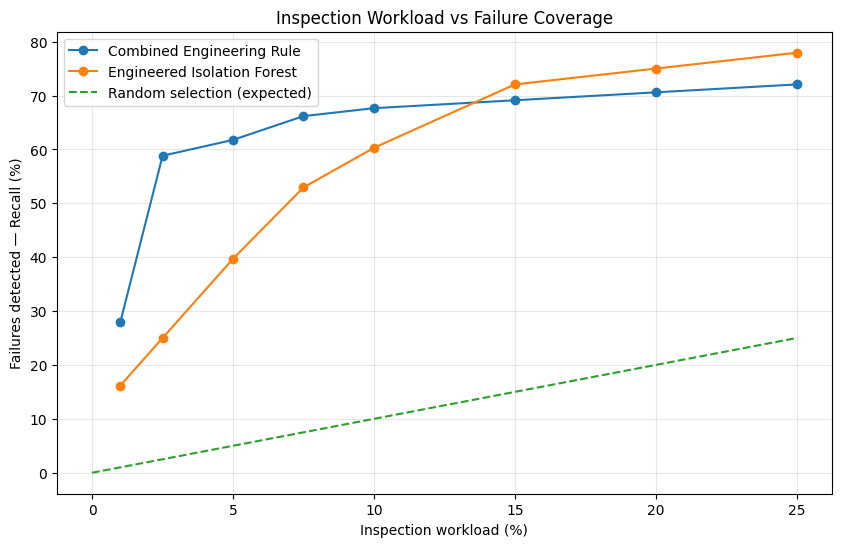

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for name, group in budget_analysis.groupby("Strategy"):

    plt.plot(
        group["Workload (%)"],
        group["Recall (%)"],
        marker="o",
        label=name
    )

plt.plot(
    [0, 25],
    [0, 25],
    linestyle="--",
    label="Random selection (expected)"
)

plt.xlabel("Inspection workload (%)")
plt.ylabel("Failures detected — Recall (%)")
plt.title("Inspection Workload vs Failure Coverage")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [50]:
failure_types = [
    "TWF", "HDF", "PWF", "OSF", "RNF"
]

test_failure_types = df.loc[
    X_test9.index,
    failure_types
].copy()

test_failure_types["Machine failure"] = y_test9

display(
    test_failure_types[
        test_failure_types["Machine failure"] == 1
    ][failure_types].sum()
)

,0
TWF,8
HDF,21
PWF,18
OSF,24
RNF,0


In [52]:
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]

test_failure_types = df.loc[
    X_test9.index,
    failure_types
].copy()

test_failure_types["Machine failure"] = y_test9

strategies = {
    "Engineering Rule": test_max_scores,
    "Isolation Forest": test_if_scores
}

mechanism_results = []

for k in [50, 100, 500]:

    for name, scores in strategies.items():

        selected = scores.nlargest(k).index

        for failure in failure_types:

            actual = (
                (test_failure_types[failure] == 1)
                & (y_test9 == 1)
            )

            total = int(actual.sum())
            detected = int(actual.loc[selected].sum())

            mechanism_results.append({
                "Strategy": name,
                "Budget": k,
                "Failure Type": failure,
                "Total Failures": total,
                "Detected": detected,
                "Missed": total - detected,
                "Recall (%)": (
                    detected / total * 100
                    if total > 0 else np.nan
                )
            })

mechanism_analysis = pd.DataFrame(mechanism_results)

print("Shape:", mechanism_analysis.shape)

display(mechanism_analysis.round(2))

Shape: (30, 7)


,Strategy,Budget,Failure Type,Total Failures,Detected,Missed,Recall (%)
0,Engineering Rule,50,TWF,8,1,7,12.50
1,Engineering Rule,50,HDF,21,1,20,4.76
2,Engineering Rule,50,PWF,18,18,0,100.00
3,Engineering Rule,50,OSF,24,24,0,100.00
4,Engineering Rule,50,RNF,0,0,0,NaN
5,Isolation Forest,50,TWF,8,1,7,12.50
6,Isolation Forest,50,HDF,21,1,20,4.76
7,Isolation Forest,50,PWF,18,8,10,44.44
8,Isolation Forest,50,OSF,24,11,13,45.83
9,Isolation Forest,50,RNF,0,0,0,NaN


In [53]:
mechanism_comparison = mechanism_analysis.pivot(
    index=["Budget", "Failure Type", "Total Failures"],
    columns="Strategy",
    values="Detected"
)

display(mechanism_comparison)

Strategy                            Engineering Rule  Isolation Forest
Budget Failure Type Total Failures                                    
50     HDF          21                             1                 1
       OSF          24                            24                11
       PWF          18                            18                 8
       RNF          0                              0                 0
       TWF          8                              1                 1
100    HDF          21                             3                 3
       OSF          24                            24                14
       PWF          18                            18                13
       RNF          0                              0                 0
       TWF          8                              1                 1
500    HDF          21                             6                13
       OSF          24                            24                24
       PWF          18                            18                18
       RNF          0                              0                 0
       TWF          8                              5                 2

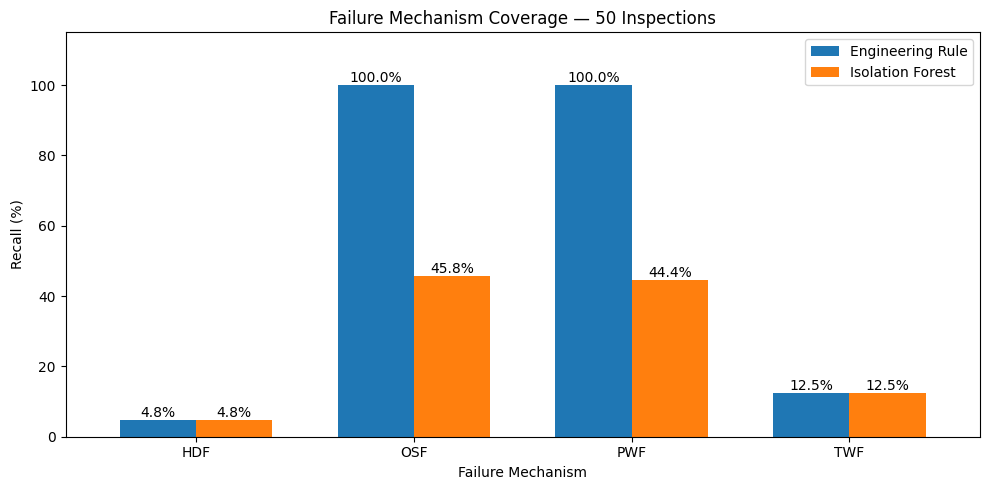

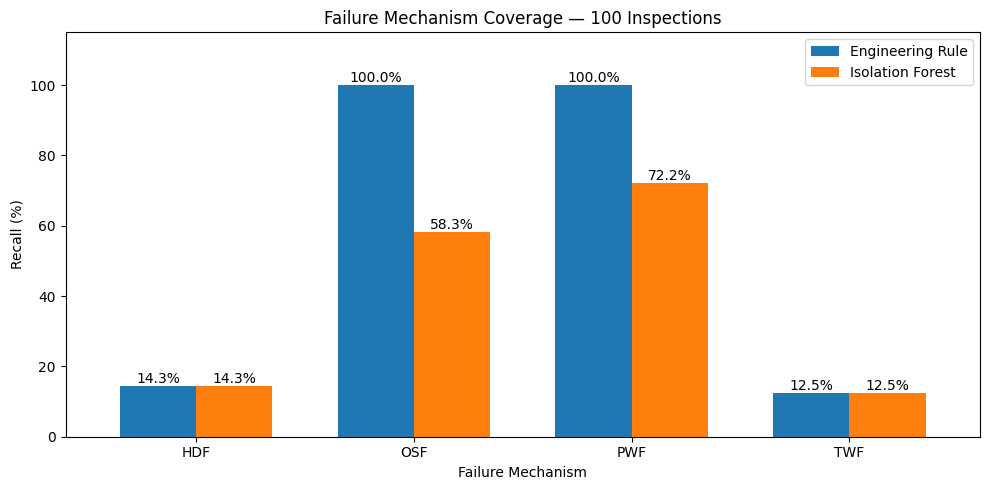

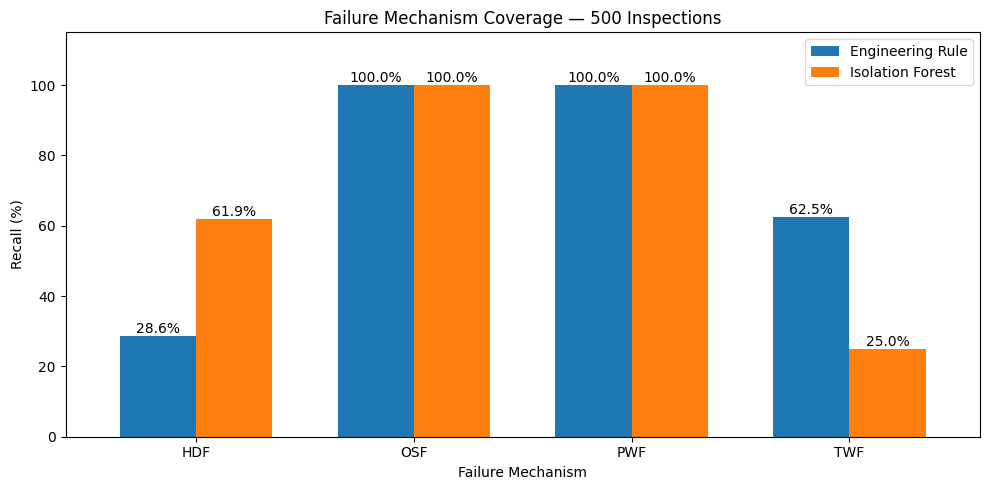

In [54]:
import matplotlib.pyplot as plt

for k in [50, 100, 500]:

    plot_data = mechanism_analysis[
        (mechanism_analysis["Budget"] == k)
        & (mechanism_analysis["Total Failures"] > 0)
    ].pivot(
        index="Failure Type",
        columns="Strategy",
        values="Recall (%)"
    )

    ax = plot_data.plot(
        kind="bar",
        figsize=(10, 5),
        width=0.7
    )

    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%")

    plt.title(
        f"Failure Mechanism Coverage — {k} Inspections"
    )

    plt.ylabel("Recall (%)")
    plt.xlabel("Failure Mechanism")
    plt.xticks(rotation=0)
    plt.ylim(0, 115)
    plt.legend()
    plt.tight_layout()
    plt.show()